# PART 3: TEXT ANALYSIS AND SENTIMENT CLASSIFICATION

## 1. Introduction

Customer reviews can give organisations important insight into customer experiences, satisfaction and service issues. Members of medical aid schemes provide feedback on matters including claims, benefit coverage, communication, administration and customer service.

This study analyses reviews of Bonitas Medical Fund posted on HelloPeter. Using text analytics and machine learning, it seeks to identify prevalent causes of customer dissatisfaction and examine the overall sentiment conveyed in the reviews. 

The methods include exploratory data analysis and text preprocessing, followed by TF-IDF feature extraction, Non-negative Matrix Factorisation (NMF) for topic modelling, and sentiment classification with Multinomial Naive Bayes and Logistic Regression.

The results will help reveal persistent customer concerns and guide recommendations aimed at improving service delivery

In [1]:
# Import libraries for data analysis and visualisation

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import warnings

# Import text analysis tools
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import NMF

# Import machine learning tools
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Dataset Selection and Description

The dataset selected for this analysis was collected from HelloPeter and contains customer reviews about Bonitas Medical Fund, a South African medical aid provider.

The dataset contains 250 reviews and 52 original columns. The relevant information includes the review title, review text, customer rating, publication date, company information and whether the business responded to the review.

The dataset is appropriate for text analysis because it comprises written customer feedback that can be reviewed to identify recurring vocabulary, themes, and expressions of dissatisfaction.

The rating field provides a basis for deriving sentiment categories. Ratings of one or two stars are designated as negative, while ratings from three to five stars are classified as non-negative.

However, the dataset is subject to limitations. Its reviews were submitted voluntarily by customers and do not constitute a random sample of all Bonitas members. The results therefore cannot be assumed to reflect the experiences of every member.

In [2]:
# Load the HelloPeter dataset

df = pd.read_csv("hellopeter_medical_aid_reviews 2.csv")

# Display the first five records
df.head()

,authorMemberSince,authorName,averageResponseTimeHours,companyAddress,companyEmail,companyName,companyPhone,companySlug,companyUrl,companyWebsite,...,replyCount,reviewId,reviewUrl,reviewsLast12Months,scrapedAt,starRating,text,title,totalReviews,trustIndex
0,Nov 2026,T D,94.87,"37 Conrad Street, Roodepoort, Florida North, 1708",queries@bonitas.co.za,Bonitas Medical Fund,860002108,bonitas,https://www.hellopeter.com/bonitas,www.bonitas.co.za,...,0,9c251b49-1298-4440-9a3a-3a152052eca8,https://www.hellopeter.com/bonitas/reviews/20-...,2257,2026-11-16T18:51:13.982483+00:00,1.18,After 20 years of unbroken loyalty as a Bonita...,20 years of loyalty ruined by Bonitas's chroni...,10459,2.25
1,Feb 2026,Nonhlanhla K,94.87,"37 Conrad Street, Roodepoort, Florida North, 1708",queries@bonitas.co.za,Bonitas Medical Fund,860002108,bonitas,https://www.hellopeter.com/bonitas,www.bonitas.co.za,...,0,6ecae4e6-ca88-4955-93cd-ac5aada869f6,https://www.hellopeter.com/bonitas/reviews/wor...,2257,2026-11-16T18:51:13.982483+00:00,1.18,Sent this email and still no response\n\n\nGoo...,Worried parent woman in last trimester,10459,2.25
2,Aug 2026,Erene G,94.87,"37 Conrad Street, Roodepoort, Florida North, 1708",queries@bonitas.co.za,Bonitas Medical Fund,860002108,bonitas,https://www.hellopeter.com/bonitas,www.bonitas.co.za,...,0,8efea80f-eaee-4f6d-9cdc-9392fa1ba90f,https://www.hellopeter.com/bonitas/reviews/unp...,2257,2026-11-16T18:51:13.982483+00:00,1.18,Unpaid emergency medical Procedure Bills!\n\nT...,Unpaid emergency medical Procedure Bills!,10459,2.25
3,Jul 2016,Tello L,94.87,"37 Conrad Street, Roodepoort, Florida North, 1708",queries@bonitas.co.za,Bonitas Medical Fund,860002108,bonitas,https://www.hellopeter.com/bonitas,www.bonitas.co.za,...,0,cb712ab3-8b77-4315-ad37-287dbe4b8a30,https://www.hellopeter.com/bonitas/reviews/bek...,2257,2026-11-16T18:51:13.982483+00:00,1.18,I would like to extend my gratitude and apprec...,BEKEZELA is a STAR,10459,2.25
4,Dec 2021,Mapule P,94.87,"37 Conrad Street, Roodepoort, Florida North, 1708",queries@bonitas.co.za,Bonitas Medical Fund,860002108,bonitas,https://www.hellopeter.com/bonitas,www.bonitas.co.za,...,1,4d436a38-3772-4c4d-93bc-d36f2c288bb2,https://www.hellopeter.com/bonitas/reviews/wor...,2257,2026-11-16T18:51:13.982483+00:00,1.18,It's been 3 months since Bonitas has been clai...,Worse of the worse customer Service…,10459,2.25


In [3]:
# Display the dataset dimensions

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Display all column names
print("\nDataset columns:")
print(df.columns.tolist())

# Display the data types and non-null values
df.info()

Number of rows: 250
Number of columns: 52

Dataset columns:
['authorMemberSince', 'authorName', 'averageResponseTimeHours', 'companyAddress', 'companyEmail', 'companyName', 'companyPhone', 'companySlug', 'companyUrl', 'companyWebsite', 'hasBusinessReply', 'helpfulCount', 'industryName', 'industryRanking', 'negativeResponseRate', 'nps', 'publishedAt', 'rating', 'replies/0/authorName', 'replies/0/authorType', 'replies/0/publishedAt', 'replies/0/text', 'replies/1/authorName', 'replies/1/authorType', 'replies/1/publishedAt', 'replies/1/text', 'replies/2/authorName', 'replies/2/authorType', 'replies/2/publishedAt', 'replies/2/text', 'replies/3/authorName', 'replies/3/authorType', 'replies/3/publishedAt', 'replies/3/text', 'replies/4/authorName', 'replies/4/authorType', 'replies/4/publishedAt', 'replies/4/text', 'replies/5/authorName', 'replies/5/authorType', 'replies/5/publishedAt', 'replies/5/text', 'replyCount', 'reviewId', 'reviewUrl', 'reviewsLast12Months', 'scrapedAt', 'starRating', 't

In [5]:
# Display basic statistical information

df.describe(include="all")

,authorMemberSince,authorName,averageResponseTimeHours,companyAddress,companyEmail,companyName,companyPhone,companySlug,companyUrl,companyWebsite,...,replyCount,reviewId,reviewUrl,reviewsLast12Months,scrapedAt,starRating,text,title,totalReviews,trustIndex
count,250,250,250.00,250,250,250,250.0,250,250,250,...,250.000000,250,250,250.0,250,250.00,250,250,250.0,250.00
unique,134,223,NaN,1,1,1,NaN,1,1,1,...,NaN,250,250,NaN,1,NaN,250,247,NaN,NaN
top,Nov 2026,Mapule P,NaN,"37 Conrad Street, Roodepoort, Florida North, 1708",queries@bonitas.co.za,Bonitas Medical Fund,NaN,bonitas,https://www.hellopeter.com/bonitas,www.bonitas.co.za,...,NaN,9c251b49-1298-4440-9a3a-3a152052eca8,https://www.hellopeter.com/bonitas/reviews/20-...,NaN,2026-11-16T18:51:13.982483+00:00,NaN,After 20 years of unbroken loyalty as a Bonita...,Horrible,NaN,NaN
freq,17,3,NaN,250,250,250,NaN,250,250,250,...,NaN,1,1,NaN,250,NaN,1,2,NaN,NaN
mean,NaN,NaN,94.87,NaN,NaN,NaN,860002108.0,NaN,NaN,NaN,...,1.208000,NaN,NaN,2257.0,NaN,1.18,NaN,NaN,10459.0,2.25
std,NaN,NaN,0.00,NaN,NaN,NaN,0.0,NaN,NaN,NaN,...,0.591723,NaN,NaN,0.0,NaN,0.00,NaN,NaN,0.0,0.00
min,NaN,NaN,94.87,NaN,NaN,NaN,860002108.0,NaN,NaN,NaN,...,0.000000,NaN,NaN,2257.0,NaN,1.18,NaN,NaN,10459.0,2.25
25%,NaN,NaN,94.87,NaN,NaN,NaN,860002108.0,NaN,NaN,NaN,...,1.000000,NaN,NaN,2257.0,NaN,1.18,NaN,NaN,10459.0,2.25
50%,NaN,NaN,94.87,NaN,NaN,NaN,860002108.0,NaN,NaN,NaN,...,1.000000,NaN,NaN,2257.0,NaN,1.18,NaN,NaN,10459.0,2.25
75%,NaN,NaN,94.87,NaN,NaN,NaN,860002108.0,NaN,NaN,NaN,...,1.000000,NaN,NaN,2257.0,NaN,1.18,NaN,NaN,10459.0,2.25


## 3. Data Cleaning and Preparation

Data cleaning is an important stage because incomplete, duplicated or incorrectly formatted information can affect the quality of the analysis.

The review text and rating fields were selected as the main variables for this analysis. The title was also retained because it provides additional information about the customer's experience.

The publication date was converted into a datetime format, while the rating was converted into a numeric variable. Records with missing review text, empty reviews, invalid ratings or duplicate review text were checked and removed where necessary.

The dataset was also prepared for text processing by combining the review title and review body into a single text field.

In [6]:
# Select the relevant columns

data = df[
    [
        "reviewId",
        "reviewUrl",
        "companyName",
        "publishedAt",
        "rating",
        "title",
        "text",
        "hasBusinessReply",
        "replyCount"
    ]
].copy()

# Convert publication date into datetime format
data["publishedAt"] = pd.to_datetime(
    data["publishedAt"],
    errors="coerce",
    utc=True
)

# Convert ratings to numeric values
data["rating"] = pd.to_numeric(
    data["rating"],
    errors="coerce"
)

# Remove records with missing review text or ratings
data = data.dropna(subset=["text", "rating"])

# Convert review text to strings
data["text"] = data["text"].astype(str)

# Remove empty reviews
data = data[data["text"].str.strip() != ""]

# Keep valid ratings between 1 and 5
data = data[data["rating"].between(1, 5)]

# Remove duplicate review text
data = data.drop_duplicates(subset=["text"])

# Combine the title and review body
data["title"] = data["title"].fillna("").astype(str)

data["combined_text"] = (
    data["title"] + " " + data["text"]
).str.strip()

# Calculate review length
data["word_count"] = data["combined_text"].str.split().str.len()

# Display cleaned dataset information
print("Cleaned dataset shape:", data.shape)
print("Missing review texts:", data["text"].isna().sum())
print("Duplicate reviews:", data["text"].duplicated().sum())

data.head()

Cleaned dataset shape: (250, 11)
Missing review texts: 0
Duplicate reviews: 0


,reviewId,reviewUrl,companyName,publishedAt,rating,title,text,hasBusinessReply,replyCount,combined_text,word_count
0,9c251b49-1298-4440-9a3a-3a152052eca8,https://www.hellopeter.com/bonitas/reviews/20-...,Bonitas Medical Fund,2026-11-16 15:49:14.968000+00:00,1,20 years of loyalty ruined by Bonitas's chroni...,After 20 years of unbroken loyalty as a Bonita...,False,0,20 years of loyalty ruined by Bonitas's chroni...,470
1,6ecae4e6-ca88-4955-93cd-ac5aada869f6,https://www.hellopeter.com/bonitas/reviews/wor...,Bonitas Medical Fund,2026-11-16 14:48:17.860000+00:00,1,Worried parent woman in last trimester,Sent this email and still no response\n\n\nGoo...,False,0,Worried parent woman in last trimester Sent t...,715
2,8efea80f-eaee-4f6d-9cdc-9392fa1ba90f,https://www.hellopeter.com/bonitas/reviews/unp...,Bonitas Medical Fund,2026-11-16 14:29:11.175000+00:00,1,Unpaid emergency medical Procedure Bills!,Unpaid emergency medical Procedure Bills!\n\nT...,False,0,Unpaid emergency medical Procedure Bills! Unpa...,343
3,cb712ab3-8b77-4315-ad37-287dbe4b8a30,https://www.hellopeter.com/bonitas/reviews/bek...,Bonitas Medical Fund,2026-11-16 14:11:01.471000+00:00,4,BEKEZELA is a STAR,I would like to extend my gratitude and apprec...,False,0,BEKEZELA is a STAR I would like to extend my g...,139
4,4d436a38-3772-4c4d-93bc-d36f2c288bb2,https://www.hellopeter.com/bonitas/reviews/wor...,Bonitas Medical Fund,2026-11-16 09:17:32.411000+00:00,1,Worse of the worse customer Service…,It's been 3 months since Bonitas has been clai...,True,1,Worse of the worse customer Service… It's bee...,61


# Dataset quality and suitability

The cleaned sample contains 250 reviews. There are no missing review texts and no duplicate review texts in this sample. The ratings range from one to five stars. The sample covers 16 October 2026 to 16 November 2026.
The data is suitable for exploratory text analysis because it contains natural-language customer feedback and star ratings. It is not a random sample of all Bonitas members.

## 4. Exploratory Data Analysis

Exploratory Data Analysis (EDA) was carried out to characterise the distribution of customer ratings, review lengths, and the overall sentiment present in customer feedback.

The rating distribution warrants particular attention because it serves as an initial indicator of customer satisfaction. Review length was additionally examined to assess how much written information customers contributed.

Visualisations were employed to detect patterns and possible imbalances within the dataset before machine learning algorithms were implemented.

rating
1    235
2      7
3      1
4      3
5      4
Name: count, dtype: int64


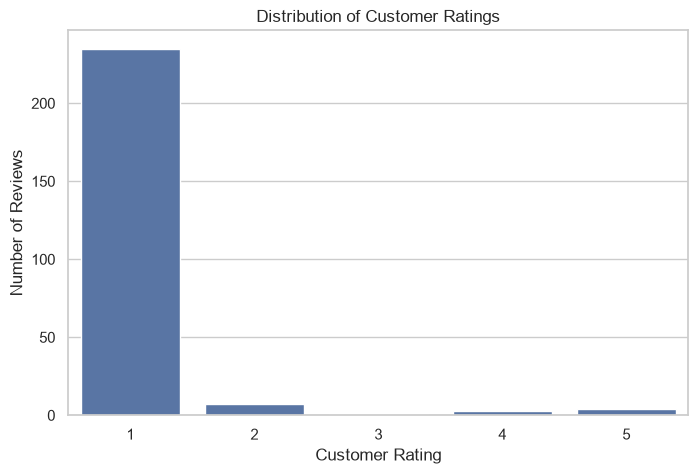

In [7]:
# Calculate the number of reviews for each rating

rating_counts = data["rating"].value_counts().sort_index()

print(rating_counts)

# Create a bar chart
plt.figure(figsize=(8, 5))

sns.barplot(
    x=rating_counts.index,
    y=rating_counts.values
)

plt.title("Distribution of Customer Ratings")
plt.xlabel("Customer Rating")
plt.ylabel("Number of Reviews")
plt.xticks([0, 1, 2, 3, 4], ["1", "2", "3", "4", "5"])

plt.show()

### Interpretation of Customer Ratings

The rating distribution shows that the dataset is heavily dominated by one-star reviews. Out of the 250 reviews, 235 received one star and seven received two stars. Only eight reviews received ratings between three and five stars.

This indicates that the collected reviews contain a strong concentration of negative customer experiences.

The distribution additionally highlights considerable class imbalance. This is significant because models trained on this dataset may favor the predominant negative class, making non-negative reviews harder to recognize.

sentiment
Negative        242
Non-negative      8
Name: count, dtype: int64


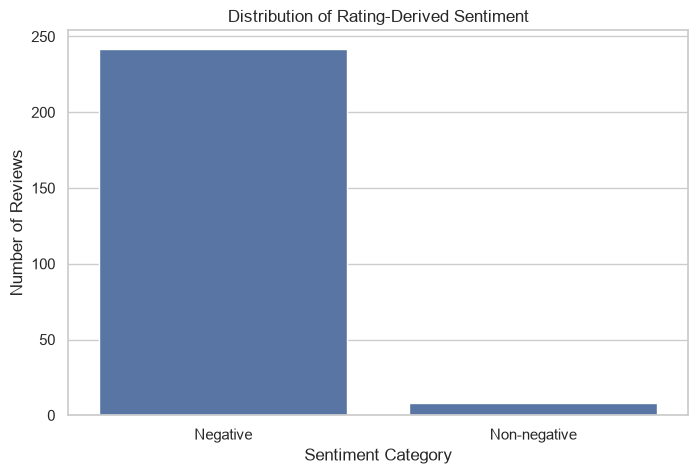

In [8]:
# Create sentiment categories using customer ratings

def assign_sentiment(rating):
    if rating <= 2:
        return "Negative"
    else:
        return "Non-negative"

data["sentiment"] = data["rating"].apply(assign_sentiment)

# Display sentiment distribution
sentiment_counts = data["sentiment"].value_counts()

print(sentiment_counts)

# Visualise sentiment distribution
plt.figure(figsize=(8, 5))

sns.countplot(
    data=data,
    x="sentiment"
)

plt.title("Distribution of Rating-Derived Sentiment")
plt.xlabel("Sentiment Category")
plt.ylabel("Number of Reviews")

plt.show()

### Interpretation of Sentiment Distribution

The sentiment distribution indicates that 242 reviews are classified as negative, while only eight are classified as non-negative.

Negative reviews account for 96.8% of the dataset, demonstrating a substantial imbalance between the two categories.

The sentiment labels are derived from customer ratings rather than manually verified sentiment annotations. Therefore, they represent rating-based sentiment categories and may not always perfectly reflect the language used in each review.

count     250.000000
mean      149.704000
std       154.793451
min        11.000000
25%        55.250000
50%       105.000000
75%       186.750000
max      1614.000000
Name: word_count, dtype: float64


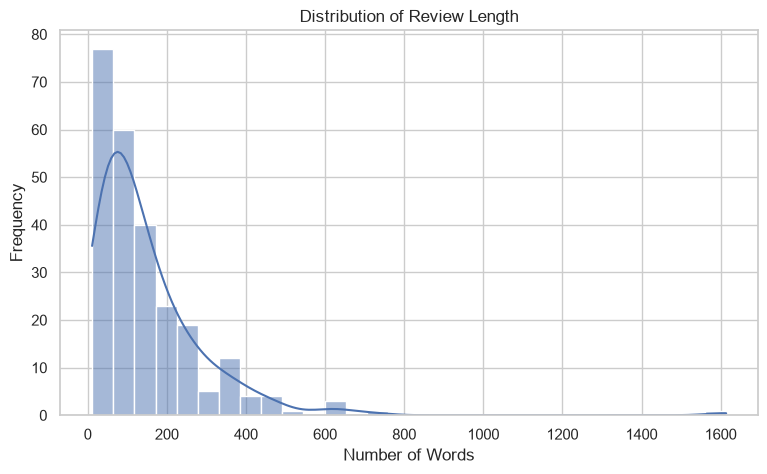

In [9]:
# Display descriptive statistics for review length

print(data["word_count"].describe())

# Plot the distribution of review length
plt.figure(figsize=(9, 5))

sns.histplot(
    data["word_count"],
    bins=30,
    kde=True
)

plt.title("Distribution of Review Length")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.show()

### Interpretation of Review Length

The average review contains approximately 150 words, whereas the median review contains 105 words.

This indicates substantial variation in the detail customers provide about their experiences. While some reviews are short and complaint-focused, others elaborate on claims, medical benefits, administrative difficulties, and communication barriers.

The availability of this detailed feedback supports the use of the dataset for text analytics and topic modelling.

## 5. Text Preprocessing

Text preprocessing prepares written reviews for machine learning analysis.

The review text was converted to lowercase, URLs and email addresses were removed, and punctuation and numerical characters were removed. Extra spaces were also eliminated.

Common English stop words were removed during feature extraction. However, negation words such as "not", "no" and "nor" were retained because they can change the meaning of a customer review.

The cleaned text was subsequently used for TF-IDF feature extraction.

In [10]:
# Function to clean customer review text

def clean_text(text):

    text = str(text).lower()

    # Remove website URLs
    text = re.sub(r"http\S+|www\.\S+", " ", text)

    # Remove email addresses
    text = re.sub(r"\S+@\S+", " ", text)

    # Keep alphabetic characters and spaces
    text = re.sub(r"[^a-z\s]", " ", text)

    # Remove unnecessary spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text


# Apply text cleaning
data["clean_text"] = data["combined_text"].apply(clean_text)

# Display original and cleaned text
data[["combined_text", "clean_text"]].head()

,combined_text,clean_text
0,20 years of loyalty ruined by Bonitas's chroni...,years of loyalty ruined by bonitas s chronic m...
1,Worried parent woman in last trimester Sent t...,worried parent woman in last trimester sent th...
2,Unpaid emergency medical Procedure Bills! Unpa...,unpaid emergency medical procedure bills unpai...
3,BEKEZELA is a STAR I would like to extend my g...,bekezela is a star i would like to extend my g...
4,Worse of the worse customer Service… It's bee...,worse of the worse customer service it s been ...


## 6. Feature Extraction Using TF-IDF

Machine learning methods require numeric inputs, so raw customer reviews were converted into numerical feature vectors using Term Frequency–Inverse Document Frequency (TF-IDF).

TF-IDF estimates a word's significance by considering how often it occurs in an individual review relative to its prevalence throughout the review collection.

Both unigrams and bigrams were included in the analysis. A unigram is a single word, while a bigram is a sequence of two adjacent words. Including bigrams helps retain meaningful expressions such as "customer service", "medical aid" and "unpaid claims".

To keep the feature space manageable, the maximum number of features was set to 1,500. Any term found in fewer than two reviews was excluded.

In [11]:
# Preserve important negation words
custom_stop_words = list(
    ENGLISH_STOP_WORDS.difference({"not", "no", "nor"})
)

# Create the TF-IDF vectorizer
tfidf = TfidfVectorizer(
    stop_words=custom_stop_words,
    max_features=1500,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95
)

# Convert cleaned text into numerical features
tfidf_matrix = tfidf.fit_transform(data["clean_text"])

print("TF-IDF matrix shape:", tfidf_matrix.shape)
print("Number of extracted features:", len(tfidf.get_feature_names_out()))

TF-IDF matrix shape: (250, 1500)
Number of extracted features: 1500


## 7. Topic Modelling Using Non-negative Matrix Factorisation

Non-negative Matrix Factorisation (NMF) was selected to identify common themes within the customer reviews.

NMF is an unsupervised learning technique that identifies groups of words that frequently occur together. These word groups can help reveal broad areas of customer concern without requiring predefined topic labels.

Five topics were selected to provide a manageable overview of the main issues discussed in the reviews.

The model was trained using the TF-IDF feature matrix. The most important words associated with each topic were examined to interpret the possible customer concerns represented by that topic.

The topics are machine-generated patterns and require human interpretation. They should not be treated as confirmed categories.

In [12]:
# Train the NMF topic modelling algorithm

number_of_topics = 5

nmf_model = NMF(
    n_components=number_of_topics,
    random_state=42,
    max_iter=500,
    init="nndsvda"
)

# Fit the model and obtain topic weights
topic_matrix = nmf_model.fit_transform(tfidf_matrix)

# Obtain feature names
terms = np.array(tfidf.get_feature_names_out())

# Display the top words for each topic
for topic_number, topic in enumerate(nmf_model.components_):

    top_indices = topic.argsort()[-12:][::-1]

    top_words = terms[top_indices]

    print("\nTopic", topic_number + 1)
    print(", ".join(top_words))


Topic 1
refund, claim, savings, no, bonitas, paid, email, not, th, october, phone, told

Topic 2
aid, medical aid, medical, bonitas, month, bonitas medical, money, no, useless, not, useless medical, pay

Topic 3
claims, maternity, benefits, bonitas, medication, matter, maternity benefits, not, chronic, membership, outstanding, resolve

Topic 4
service, terrible, bonitas, customer, customer service, no, terrible service, poor, weeks, ve, worst, pathetic

Topic 5
hospital, not, claims, bonitas, bills, june, paid, authorisation, hospital bills, not paid, called, pay


In [13]:
# Assign each review to the topic with the highest topic weight

data["topic"] = topic_matrix.argmax(axis=1) + 1

# Count the number of reviews assigned to each topic
topic_counts = data["topic"].value_counts().sort_index()

print(topic_counts)

# Calculate topic percentages
topic_percentages = (
    topic_counts / len(data) * 100
).round(1)

print("\nTopic percentages:")
print(topic_percentages)

topic
1    52
2    57
3    49
4    62
5    30
Name: count, dtype: int64

Topic percentages:
topic
1    20.8
2    22.8
3    19.6
4    24.8
5    12.0
Name: count, dtype: float64


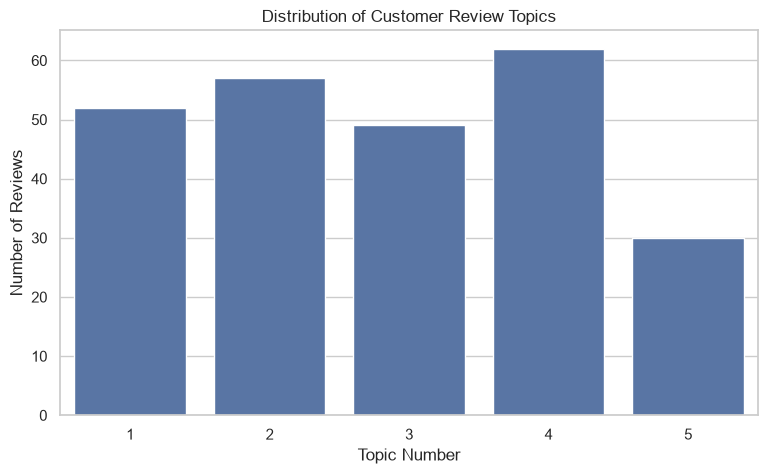

In [14]:
# Plot the number of reviews assigned to each topic

plt.figure(figsize=(9, 5))

sns.barplot(
    x=topic_counts.index,
    y=topic_counts.values
)

plt.title("Distribution of Customer Review Topics")
plt.xlabel("Topic Number")
plt.ylabel("Number of Reviews")

plt.show()

### Interpretation of Topic Modelling Results

The NMF model identified five broad topics within the 250 customer reviews.

Topic 1 contains words associated with refunds, claims, savings and payments. This suggests that some customers are concerned about financial transactions, outstanding payments and refund-related matters.

Topic 2 contains words associated with medical aid membership, money and contributions. This indicates concerns relating to membership administration and the financial value of the medical aid service.

Topic 3 contains words associated with claims, maternity benefits and chronic medication. This suggests that customers experience concerns relating to benefit administration, medication and claims processing.

Topic 4 contains words associated with service, customer service and poor communication. This indicates that customer support and the quality of service delivery are important areas of concern.

Topic 5 contains words associated with hospital claims, authorisation and unpaid bills. This suggests concerns relating to hospital-related claims and payment arrangements.

Topic 4 was the largest topic, representing 24.4% of the reviews, followed by Topic 2 at 22.8%. These results indicate that service delivery, communication, membership-related concerns and claims administration are important areas requiring further investigation.

The topic labels are interpretations of the most prominent words generated by the NMF model rather than manually verified classifications.

## 8. Sentiment Classification

The analysis used sentiment classification to determine whether machine learning methods could distinguish negative reviews from non-negative reviews.

Customer ratings provided the basis for the sentiment labels. Reviews with one or two stars were labeled negative; those with three, four, or five stars were grouped as non-negative.

Two algorithms were selected for classification.

Multinomial Naive Bayes was used as the baseline because it is widely applied to text classification and supports non-negative numerical representations of text, such as TF-IDF features.

Logistic Regression provided a comparison model. As a supervised classification algorithm, it can identify relationships between text features and sentiment categories.

An 80:20 split was used to create the training and testing subsets. Stratified sampling helped preserve the dataset’s original class proportions.

TF-IDF was placed within each machine learning pipeline to ensure the vectorizer was fitted exclusively on the training subset. This approach mitigates the potential for data leakage.

In [15]:
# Define the input text and target sentiment

X = data["clean_text"]
y = data["sentiment"]

# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining sentiment distribution:")
print(y_train.value_counts())

print("\nTesting sentiment distribution:")
print(y_test.value_counts())

Training records: 200
Testing records: 50

Training sentiment distribution:
sentiment
Negative        194
Non-negative      6
Name: count, dtype: int64

Testing sentiment distribution:
sentiment
Negative        48
Non-negative     2
Name: count, dtype: int64


In [16]:
# Create the Naive Bayes machine learning pipeline

nb_model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            stop_words=custom_stop_words,
            max_features=1500,
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95
        )
    ),
    ("classifier", MultinomialNB())
])

# Train the model
nb_model.fit(X_train, y_train)

# Make predictions
nb_predictions = nb_model.predict(X_test)

# Evaluate the model
nb_accuracy = accuracy_score(y_test, nb_predictions)

nb_macro_f1 = f1_score(
    y_test,
    nb_predictions,
    average="macro",
    zero_division=0
)

print("Naive Bayes Accuracy:", nb_accuracy)
print("Naive Bayes Macro F1:", nb_macro_f1)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        nb_predictions,
        zero_division=0
    )
)

Naive Bayes Accuracy: 0.96
Naive Bayes Macro F1: 0.4897959183673469

Classification Report:
              precision    recall  f1-score   support

    Negative       0.96      1.00      0.98        48
Non-negative       0.00      0.00      0.00         2

    accuracy                           0.96        50
   macro avg       0.48      0.50      0.49        50
weighted avg       0.92      0.96      0.94        50



In [17]:
# Create the Logistic Regression pipeline

lr_model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            stop_words=custom_stop_words,
            max_features=1500,
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95
        )
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        )
    )
])

# Train the model
lr_model.fit(X_train, y_train)

# Generate predictions
lr_predictions = lr_model.predict(X_test)

# Evaluate Logistic Regression
lr_accuracy = accuracy_score(y_test, lr_predictions)

lr_macro_f1 = f1_score(
    y_test,
    lr_predictions,
    average="macro",
    zero_division=0
)

print("Logistic Regression Accuracy:", lr_accuracy)
print("Logistic Regression Macro F1:", lr_macro_f1)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        lr_predictions,
        zero_division=0
    )
)

Logistic Regression Accuracy: 0.96
Logistic Regression Macro F1: 0.4897959183673469

Classification Report:
              precision    recall  f1-score   support

    Negative       0.96      1.00      0.98        48
Non-negative       0.00      0.00      0.00         2

    accuracy                           0.96        50
   macro avg       0.48      0.50      0.49        50
weighted avg       0.92      0.96      0.94        50



In [18]:
# Compare the two classification algorithms

model_comparison = pd.DataFrame({
    "Model": [
        "Multinomial Naive Bayes",
        "Logistic Regression"
    ],
    "Accuracy": [
        nb_accuracy,
        lr_accuracy
    ],
    "Macro F1 Score": [
        nb_macro_f1,
        lr_macro_f1
    ]
})

print(model_comparison)

                     Model  Accuracy  Macro F1 Score
0  Multinomial Naive Bayes      0.96        0.489796
1      Logistic Regression      0.96        0.489796


### Interpretation of Classification Results

Both Multinomial Naive Bayes and Logistic Regression achieved an accuracy of 96% on the test dataset.

However, accuracy alone does not provide a complete picture of model performance because the dataset contains a substantial imbalance between negative and non-negative reviews.

Both models correctly classified the 48 negative reviews in the test set but failed to identify the two non-negative reviews.

The macro F1-score was approximately 0.49 for both models. This indicates that the models did not perform equally well across the two sentiment categories.

Although the overall accuracy appears high, the results demonstrate that the classifiers are strongly influenced by the majority negative class.

Therefore, neither model can currently be considered reliable for identifying non-negative sentiment. A larger and more balanced dataset would be required to improve classification performance.

## 9. Model Improvement and Hyperparameter Tuning

Hyperparameter optimisation was conducted to assess the potential for improving the Logistic Regression model’s classification performance.

Grid Search, incorporating three-fold stratified cross-validation, was applied to examine alternative values of the regularisation parameter C and class weights.

The macro F1-score served as the optimisation criterion, as it assigns equal importance to performance across sentiment categories. This makes it more appropriate than accuracy alone for an imbalanced dataset.

Only the training data was used during the search; the test data was reserved for the final evaluation.

In [19]:
# Define the hyperparameters to test

param_grid = {
    "classifier__C": [0.1, 1, 5, 10],
    "classifier__class_weight": [None, "balanced"]
}

# Configure stratified cross-validation
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Create Grid Search
grid_search = GridSearchCV(
    estimator=lr_model,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1
)

# Train the Grid Search model
grid_search.fit(X_train, y_train)

# Display the best parameters
print("Best parameters:")
print(grid_search.best_params_)

print("\nBest cross-validation Macro F1:")
print(grid_search.best_score_)

Best parameters:
{'classifier__C': 0.1, 'classifier__class_weight': None}

Best cross-validation Macro F1:
0.4923853923853924


In [20]:
# Retrieve the best model
best_model = grid_search.best_estimator_

# Generate predictions using the test data
best_predictions = best_model.predict(X_test)

# Calculate evaluation metrics
best_accuracy = accuracy_score(
    y_test,
    best_predictions
)

best_macro_f1 = f1_score(
    y_test,
    best_predictions,
    average="macro",
    zero_division=0
)

print("Improved Model Accuracy:", best_accuracy)
print("Improved Model Macro F1:", best_macro_f1)

print("\nImproved Model Classification Report:")

print(
    classification_report(
        y_test,
        best_predictions,
        zero_division=0
    )
)

Improved Model Accuracy: 0.96
Improved Model Macro F1: 0.4897959183673469

Improved Model Classification Report:
              precision    recall  f1-score   support

    Negative       0.96      1.00      0.98        48
Non-negative       0.00      0.00      0.00         2

    accuracy                           0.96        50
   macro avg       0.48      0.50      0.49        50
weighted avg       0.92      0.96      0.94        50



### Interpretation of Model Improvement

Grid Search was used to test different Logistic Regression hyperparameter combinations. The best parameter combination was C = 0.1 and class_weight = None, with a cross-validation macro F1-score of approximately 0.4924.

However, the improved model achieved the same test accuracy and macro F1-score as the original models.

This indicates that hyperparameter tuning did not meaningfully improve the classification performance.

The main limitation is the lack of non-negative examples. Hyperparameter tuning cannot fully compensate for an insufficient number of examples in the minority category.

A larger dataset containing more positive and neutral reviews would be necessary to train a more balanced and reliable sentiment classifier.

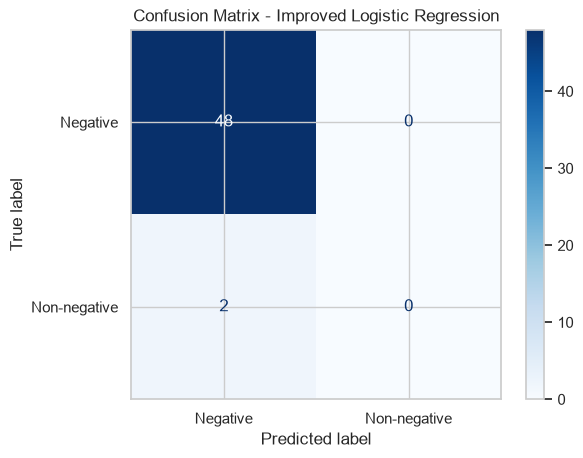

In [21]:
# Display the confusion matrix for the improved model

labels = ["Negative", "Non-negative"]

cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=labels
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

disp.plot(cmap="Blues")

plt.title("Confusion Matrix - Improved Logistic Regression")

plt.show()

### Interpretation of Confusion Matrix

The confusion matrix shows that the improved Logistic Regression model correctly classified 48 negative reviews.

However, it failed to identify both non-negative reviews in the test dataset.

This demonstrates that the model favours the majority negative class and does not generalise effectively to the minority category.

The confusion matrix supports the conclusion that the model's high accuracy is misleading when considered without precision, recall and macro F1-score.

The classification results should therefore be interpreted cautiously.

## 10. Overall Findings and Business Recommendations

An analysis of Bonitas Medical Fund reviews identified a number of customer concerns that appeared repeatedly.

Topic modelling grouped the reviews into five broad areas:

1. Refunds and payment-related concerns.
2. Membership and contribution-related concerns.
3. Claims processing and benefit administration.
4. Customer service and communication.
5. Hospital claims, authorisation and unpaid bills.

The largest topic was customer service, which comprised 24.4% of reviews. Membership and contribution-related issues represented 22.8%, while refunds and payment-related issues made up 20.8%.

The findings point to the need for attention to service delivery, communication, financial administration and claims processing.

The following actions are recommended:

- Provide members with timely and consistent responses to their enquiries.
- Assess claims processing procedures to address delays and make the process more transparent.
- Enhance the handling of hospital authorisations and unpaid medical accounts.
- Offer clearer information about benefit limits, maternity benefits and chronic medication arrangements.
- Conduct regular text analytics to track recurring complaints and detect emerging service delivery problems.
- Investigate customer service complaints to uncover operational causes and potential areas for improvement.


## 11. Limitations of the Analysis

The analysis has several limitations.

Firstly, the dataset contains only 250 reviews from Bonitas Medical Fund. The findings may not represent the experiences of all medical aid members or customers of other medical schemes.

Secondly, the reviews were collected from HelloPeter and represent voluntary customer feedback. Customers who choose to publish online reviews may have different experiences or motivations from customers who do not submit reviews.

Thirdly, the dataset contains a substantial imbalance in customer ratings. A total of 242 reviews were classified as negative, while only eight were classified as non-negative. This limited the ability of the classification algorithms to learn patterns associated with non-negative sentiment.

Fourthly, sentiment labels were derived from star ratings rather than manually annotated review text. A customer's rating may not always fully represent the sentiment expressed in the written review.

Finally, topic modelling produces groups of words that require human interpretation. The topics should therefore be treated as broad indicators of customer concerns rather than definitive classifications.

## 12. Conclusion

This analysis applied text analytics and machine learning techniques to investigate customer feedback relating to Bonitas Medical Fund.

Exploratory data analysis revealed that the dataset was dominated by one-star reviews, indicating a high concentration of negative feedback within the collected sample.

NMF topic modelling identified recurring themes involving refunds, membership, claims, benefits, customer service and hospital-related payments. These themes provide useful insight into the areas that may require further investigation by the medical aid provider.

Multinomial Naive Bayes and Logistic Regression were trained to classify rating-derived sentiment categories. Both models achieved 96% accuracy, but their macro F1-scores were approximately 0.49. The models failed to identify the minority non-negative category in the test dataset.

Overall, the analysis demonstrates how text analytics can help organisations identify recurring customer concerns from online reviews. However, improving sentiment classification would require a larger and more balanced dataset, together with more reliable sentiment labels.